<a href="https://colab.research.google.com/github/amicable594-beep/Bigdata/blob/main/week07_5692401_%EB%B0%95%EC%A2%85%EC%9C%A4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7주차 과제
빅데이터프로그래밍 · 통계학과

**이름:**박종윤
**학번:**5692401

## 과제 내용
은닉층 수와 활성화 함수를 변경하고 학습 결과를 비교합니다.

## 제출 방법
모든 셀을 실행해 출력과 그래프가 보이는 상태로 저장한 뒤 `week07_학번_이름.ipynb` 로 제출합니다.

**런타임 > 런타임 유형 변경 > T4 GPU** 를 먼저 선택하세요.


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

transform = transforms.ToTensor()
train_set = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_set  = datasets.MNIST("./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False)


device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 481kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.44MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.8MB/s]


## 공통 함수
아래 두 함수를 그대로 써서 모델만 바꿔 비교하세요.


In [ ]:
def train_model(model, epochs=5, lr=1e-3):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
        hist.append(evaluate(model))
        print(f"  epoch {epoch+1}  test acc {hist[-1][1]:.4f}")
    return model, hist


def evaluate(model):
    model.eval()
    loss_fn = nn.CrossEntropyLoss()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total


## 문제 1. 은닉층 수 비교 (35점)
은닉층이 **1개 · 2개 · 3개**인 MLP를 각각 작성해 5 epoch 학습하고, 시험 정확도를 비교하세요.
은닉층 크기는 128로 통일합니다.


In [ ]:
# 답안
# 문제 1. 은닉층 수 비교

class MLP1(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)


class MLP2(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)


class MLP3(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)


# 모델 학습
model1, hist1 = train_model(MLP1(), epochs=5)
model2, hist2 = train_model(MLP2(), epochs=5)
model3, hist3 = train_model(MLP3(), epochs=5)


# 시험 정확도 비교
acc1 = evaluate(model1)[1]
acc2 = evaluate(model2)[1]
acc3 = evaluate(model3)[1]

print("\n은닉층 수에 따른 시험 정확도 비교")
print(f"은닉층 1개: {acc1:.4f}")
print(f"은닉층 2개: {acc2:.4f}")
print(f"은닉층 3개: {acc3:.4f}")

  epoch 1  test acc 0.9349
  epoch 2  test acc 0.9515
  epoch 3  test acc 0.9626
  epoch 4  test acc 0.9685
  epoch 5  test acc 0.9732
  epoch 1  test acc 0.9420
  epoch 2  test acc 0.9619
  epoch 3  test acc 0.9656
  epoch 4  test acc 0.9713
  epoch 5  test acc 0.9723
  epoch 1  test acc 0.9489
  epoch 2  test acc 0.9632
  epoch 3  test acc 0.9637
  epoch 4  test acc 0.9728
  epoch 5  test acc 0.9741

은닉층 수에 따른 시험 정확도 비교
은닉층 1개: 0.9732
은닉층 2개: 0.9723
은닉층 3개: 0.9741


## 문제 2. 활성화 함수 비교 (35점)
은닉층 2개 모델에서 활성화 함수를 **ReLU · Sigmoid · Tanh** 로 바꿔 각각 학습하고 결과를 비교하세요.


In [ ]:
# 답안
# 문제 2. 활성화 함수 비교

class MLP_ReLU(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)


class MLP_Sigmoid(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128),
            nn.Sigmoid(),
            nn.Linear(128, 128),
            nn.Sigmoid(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)


class MLP_Tanh(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128),
            nn.Tanh(),
            nn.Linear(128, 128),
            nn.Tanh(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)


# 모델 학습
model_relu, hist_relu = train_model(MLP_ReLU(), epochs=5)
model_sigmoid, hist_sigmoid = train_model(MLP_Sigmoid(), epochs=5)
model_tanh, hist_tanh = train_model(MLP_Tanh(), epochs=5)


# 시험 정확도 비교
acc_relu = evaluate(model_relu)[1]
acc_sigmoid = evaluate(model_sigmoid)[1]
acc_tanh = evaluate(model_tanh)[1]

print("\n활성화 함수에 따른 시험 정확도 비교")
print(f"ReLU: {acc_relu:.4f}")
print(f"Sigmoid: {acc_sigmoid:.4f}")
print(f"Tanh: {acc_tanh:.4f}")

  epoch 1  test acc 0.9476
  epoch 2  test acc 0.9606
  epoch 3  test acc 0.9709
  epoch 4  test acc 0.9739
  epoch 5  test acc 0.9722
  epoch 1  test acc 0.9148
  epoch 2  test acc 0.9393
  epoch 3  test acc 0.9503
  epoch 4  test acc 0.9588
  epoch 5  test acc 0.9642
  epoch 1  test acc 0.9444
  epoch 2  test acc 0.9607
  epoch 3  test acc 0.9675
  epoch 4  test acc 0.9725
  epoch 5  test acc 0.9747

활성화 함수에 따른 시험 정확도 비교
ReLU: 0.9722
Sigmoid: 0.9642
Tanh: 0.9747


## 문제 3. 결과 비교표와 그래프 (20점)
문제 1·2의 결과를 하나의 표로 정리하고, 학습 곡선을 한 그래프에 겹쳐 그리세요.

| 모델 | 은닉층 수 | 활성화 | 파라미터 수 | 시험 정확도 |


모델 결과 비교표


,모델,은닉층 수,활성화,파라미터 수,시험 정확도
0,MLP1,1,ReLU,101770,0.9732
1,MLP2,2,ReLU,118282,0.9723
2,MLP3,3,ReLU,134794,0.9741
3,MLP_ReLU,2,ReLU,118282,0.9722
4,MLP_Sigmoid,2,Sigmoid,118282,0.9642
5,MLP_Tanh,2,Tanh,118282,0.9747


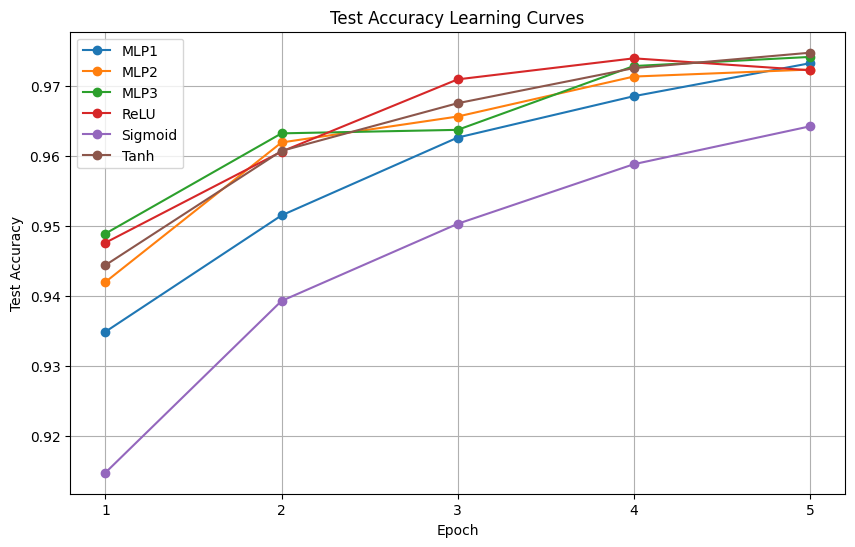

In [ ]:
# 답안
# 문제 3. 결과 비교표와 그래프

import pandas as pd
import matplotlib.pyplot as plt

# 파라미터 수 계산
def count_params(model):
    return sum(p.numel() for p in model.parameters())

# 결과 비교표
results = pd.DataFrame([
    ["MLP1", 1, "ReLU", count_params(model1), evaluate(model1)[1]],
    ["MLP2", 2, "ReLU", count_params(model2), evaluate(model2)[1]],
    ["MLP3", 3, "ReLU", count_params(model3), evaluate(model3)[1]],
    ["MLP_ReLU", 2, "ReLU", count_params(model_relu), evaluate(model_relu)[1]],
    ["MLP_Sigmoid", 2, "Sigmoid", count_params(model_sigmoid), evaluate(model_sigmoid)[1]],
    ["MLP_Tanh", 2, "Tanh", count_params(model_tanh), evaluate(model_tanh)[1]]
], columns=["모델", "은닉층 수", "활성화", "파라미터 수", "시험 정확도"])

print("모델 결과 비교표")
display(results)

# 학습 곡선
plt.figure(figsize=(10, 6))

plt.plot(range(1, 6), [h[1] for h in hist1], marker='o', label='MLP1')
plt.plot(range(1, 6), [h[1] for h in hist2], marker='o', label='MLP2')
plt.plot(range(1, 6), [h[1] for h in hist3], marker='o', label='MLP3')

plt.plot(range(1, 6), [h[1] for h in hist_relu], marker='o', label='ReLU')
plt.plot(range(1, 6), [h[1] for h in hist_sigmoid], marker='o', label='Sigmoid')
plt.plot(range(1, 6), [h[1] for h in hist_tanh], marker='o', label='Tanh')

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy Learning Curves")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True)
plt.show()

## 문제 4. 해석 (10점)
아래 세 가지를 각각 두세 줄로 적으세요.

1. 은닉층을 늘렸을 때 정확도가 어떻게 변했는가 — 계속 좋아지는가
2. Sigmoid가 ReLU보다 느리게 학습되는 이유
3. 가장 좋았던 조합과 그 이유


**답:**

1.은닉층을 늘리면 모델의 표현 능력이 증가하지만 정확도가 계속 좋아지는 것은 아닙니다
층이 많아질수록 학습이 어려워지거나 과적합이 발생할 수 있습니다.

2.Sigmoid는 입력값이 크거나 작을 때 기울기가 0에 가까워지는 기울기 소실 문제가 발생합니다.
반면 ReLU는 양수 영역에서 기울기가 1이므로 상대적으로 빠르게 학습할 수 있습니다.

3.실험 결과 은닉층 3개인 MLP 모델이 0.9741로 가장 높은 정확도를 보였으며, 활성화 함수 비교에서는 Tanh가 0.9747로 가장 높은 정확도를 보였습니다. 따라서 은닉층 3개와 Tanh를 결합한 모델이 가장 좋은 성능을 보일 것으로 예상되며, 이는 모델의 표현 능력과 활성화 함수의 특성이 성능에 영향을 주기 때문입니다.


## 문제 5. 오류 사례 확인 (보너스)
가장 좋았던 모델로 틀리게 예측한 이미지 8장을 그리고, 어떤 숫자를 어떤 숫자로 착각했는지 적으세요.


/tmp/ipykernel_1270/970774634.py:42: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1270/970774634.py:42: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1270/970774634.py:42: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1270/970774634.py:42: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-p

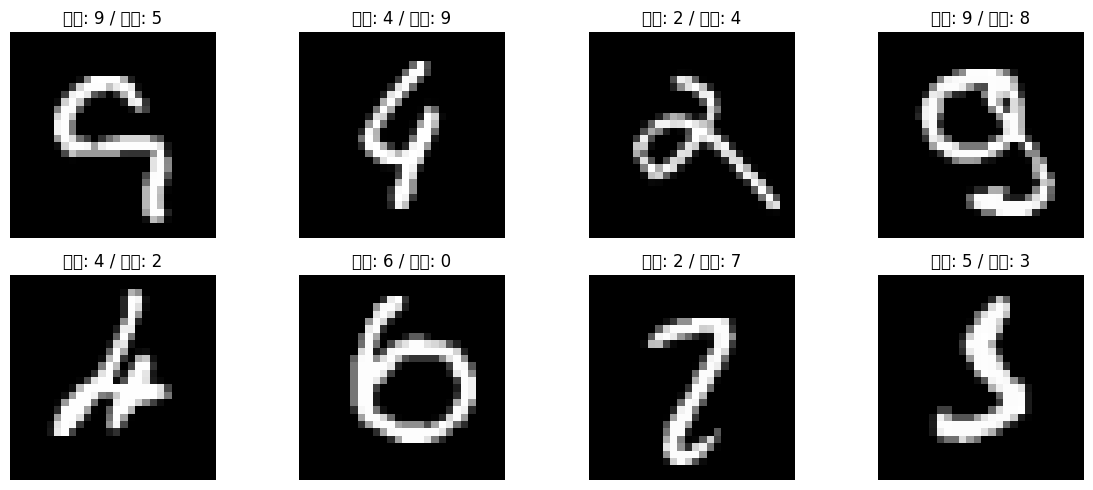

오류 사례:
1. 실제 숫자 9을(를) 5로 잘못 예측
2. 실제 숫자 4을(를) 9로 잘못 예측
3. 실제 숫자 2을(를) 4로 잘못 예측
4. 실제 숫자 9을(를) 8로 잘못 예측
5. 실제 숫자 4을(를) 2로 잘못 예측
6. 실제 숫자 6을(를) 0로 잘못 예측
7. 실제 숫자 2을(를) 7로 잘못 예측
8. 실제 숫자 5을(를) 3로 잘못 예측


In [ ]:
# 답안
# 문제 5. 오류 사례 확인 (보너스)

import matplotlib.pyplot as plt

model = model_tanh
model.eval()

wrong_images = []
wrong_labels = []
pred_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        pred = out.argmax(dim=1)

        wrong = pred != y

        for i in range(len(y)):
            if wrong[i]:
                wrong_images.append(x[i].cpu())
                wrong_labels.append(y[i].item())
                pred_labels.append(pred[i].item())

            if len(wrong_images) == 8:
                break

        if len(wrong_images) == 8:
            break

# 이미지 8장 출력
plt.figure(figsize=(12, 5))

for i in range(8):
    plt.subplot(2, 4, i+1)
    plt.imshow(wrong_images[i].squeeze(), cmap='gray')
    plt.title(f"실제: {wrong_labels[i]} / 예측: {pred_labels[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# 오분류 결과 출력
print("오류 사례:")
for i in range(8):
    print(f"{i+1}. 실제 숫자 {wrong_labels[i]}을(를) {pred_labels[i]}로 잘못 예측")